# Diabetes Prediction using KNN

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

## 2. Load the dataset

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Check the data

In [3]:
df.shape

(768, 9)

In [4]:
df.isnull().sum().sum()

0

In [5]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

## 4. Features and target

In [6]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

## 5. Train/test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 6. Scaling

In [8]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 7. Train KNN

In [9]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

## 8. Confusion matrix

[[79 20]
 [27 28]]


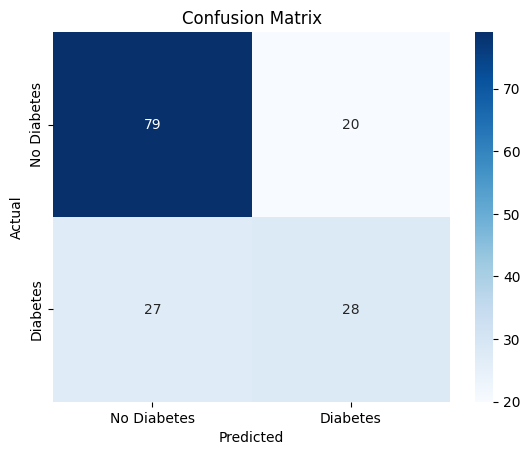

In [10]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

## 9. Accuracy, error rate, precision, recall

In [11]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Accuracy  :", accuracy)
print("Error rate:", error_rate)
print("Precision :", precision)
print("Recall    :", recall)

Accuracy  : 0.6948051948051948
Error rate: 0.30519480519480524
Precision : 0.5833333333333334
Recall    : 0.509090909090909


## 10. Graph of results

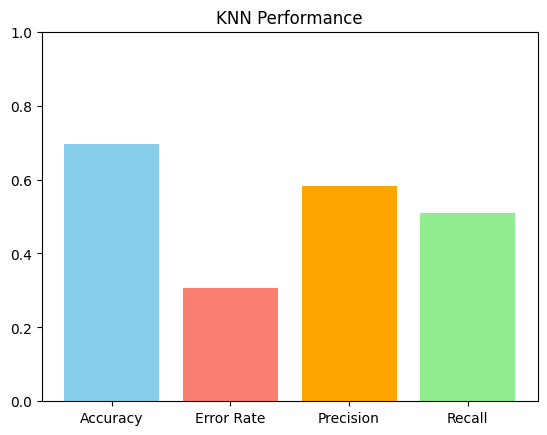

In [12]:
plt.bar(["Accuracy", "Error Rate", "Precision", "Recall"],
        [accuracy, error_rate, precision, recall],
        color=["skyblue", "salmon", "orange", "lightgreen"])
plt.title("KNN Performance")
plt.ylim(0, 1)
plt.show()